# Lab 7

Generative adversarial network
By Alex Horyshevskyi  

[Overview of GAN by IBM](https://www.ibm.com/think/topics/generative-adversarial-networks)

### Installing dependencies

In [ ]:
%pip install keras numpy scikit-learn matplotlib kagglehub librosa --quiet
%pip install --pre torch torchaudio torchcodec --index-url https://download.pytorch.org/whl/nightly/cu132 --quiet

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


### GPU check

In [1]:
import os
os.environ["KERAS_BACKEND"] = "torch"

In [2]:
import keras
import torch


print(f"Using Keras version: {keras.__version__}")
print(f"Using PyTorch version: {torch.__version__}")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Computation will be performed on: {device}")

Using Keras version: 3.14.0
Using PyTorch version: 2.13.0.dev20260428+cu132
Computation will be performed on: cuda


### Import libraries

In [3]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import kagglehub
from glob import glob
import librosa

import torch
import torchaudio
import torchaudio.transforms as T
from torch.utils.data import Dataset, DataLoader, random_split

import keras
from keras import ops
from keras.models import Sequential
from keras.layers import (
    Input, Dense, Reshape, Flatten, Dropout,
    Conv1D, Conv1DTranspose,
    Conv2D, Conv2DTranspose,
    LeakyReLU, BatchNormalization,
)
from keras.optimizers import Adam, RMSprop

keras.utils.set_random_seed(42)
torch.manual_seed(42)

OUTPUT_DIR = Path("./output")
OUTPUT_DIR.mkdir(exist_ok=True)

/mnt/shared/dev/labs/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Use Case 1: Simple 1D Audio Generation (Proof of Concept)

A Generative Adversarial Network is a two-player min-max game:

- **Generator (G)** maps a latent noise vector $z \sim \mathcal{N}(0, I)$ into a sample.
- **Discriminator (D)** takes a sample (real or generated) and outputs a probability that it is real.

The objective is:

$$
\min_G \max_D \; \mathbb{E}_{x \sim p_{\text{data}}}[\log D(x)] + \mathbb{E}_{z}[\log (1 - D(G(z)))]
$$

We start from the simplest possible audio: 1D sine waves of random frequency. If the GAN works, the generator should learn to produce sinusoidal-looking signals from random noise.

### Synthetic dataset

Real dataset shape: (1000, 4000, 1), range: [-1.09, 1.09]


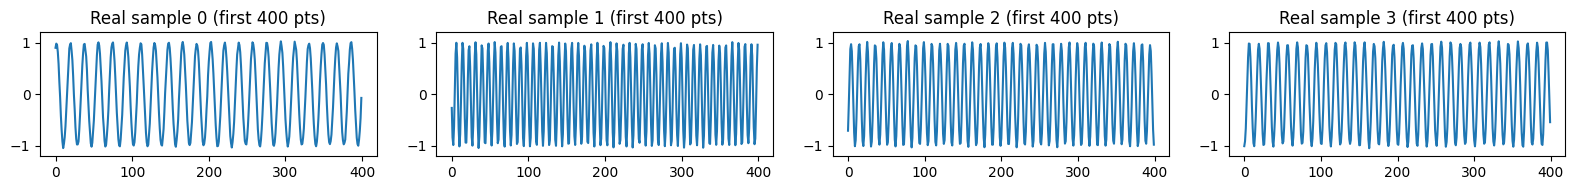

In [6]:
SAMPLE_RATE_1D = 8000
DURATION_1D = 0.5
N_SAMPLES_1D = int(SAMPLE_RATE_1D * DURATION_1D)
N_TRAIN_1D = 1000
PLOT_WINDOW = 400  # render only a short slice so individual cycles stay visible


def make_sine_dataset(n: int, length: int, sr: int) -> np.ndarray:
    t = np.arange(length) / sr
    freqs = np.random.uniform(100.0, 1000.0, size=n)
    phases = np.random.uniform(0, 2 * np.pi, size=n)
    waves = np.sin(2 * np.pi * freqs[:, np.newaxis] * t[np.newaxis, :] + phases[:, np.newaxis])
    waves = waves + np.random.normal(0, 0.02, size=waves.shape)
    return waves.astype(np.float32)[..., np.newaxis]


x_real_1d = make_sine_dataset(N_TRAIN_1D, N_SAMPLES_1D, SAMPLE_RATE_1D)
print(f"Real dataset shape: {x_real_1d.shape}, range: [{x_real_1d.min():.2f}, {x_real_1d.max():.2f}]")

fig, axes = plt.subplots(1, 4, figsize=(16, 2))
for i, ax in enumerate(axes):
    ax.plot(x_real_1d[i, :PLOT_WINDOW, 0])
    ax.set_title(f"Real sample {i} (first {PLOT_WINDOW} pts)")
    ax.set_ylim(-1.2, 1.2)
plt.tight_layout()
plt.show()

### Generator and discriminator

In [7]:
LATENT_DIM_1D = 64


def build_generator_1d() -> Sequential:
    model = Sequential(name="generator_1d")
    model.add(Input(shape=(LATENT_DIM_1D,)))
    model.add(Dense(500))
    model.add(LeakyReLU(0.2))
    model.add(Reshape((500, 1)))
    model.add(Conv1DTranspose(32, 4, strides=2, padding="same"))
    model.add(BatchNormalization())
    model.add(LeakyReLU(0.2))
    model.add(Conv1DTranspose(16, 4, strides=2, padding="same"))
    model.add(BatchNormalization())
    model.add(LeakyReLU(0.2))
    model.add(Conv1DTranspose(1, 4, strides=2, padding="same", activation="tanh"))
    return model


def build_discriminator_1d() -> Sequential:
    model = Sequential(name="discriminator_1d")
    model.add(Input(shape=(N_SAMPLES_1D, 1)))
    model.add(Conv1D(16, 4, strides=2, padding="same"))
    model.add(LeakyReLU(0.2))
    model.add(Dropout(0.3))
    model.add(Conv1D(32, 4, strides=2, padding="same"))
    model.add(LeakyReLU(0.2))
    model.add(Dropout(0.3))
    model.add(Conv1D(64, 4, strides=2, padding="same"))
    model.add(LeakyReLU(0.2))
    model.add(Dropout(0.3))
    model.add(Flatten())
    model.add(Dense(1, activation="sigmoid"))
    return model


generator_1d = build_generator_1d()
discriminator_1d = build_discriminator_1d()
generator_1d.summary()
discriminator_1d.summary()

Model: "generator_1d"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_1 (Dense)                 │ (None, 500)            │        32,500 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_3 (LeakyReLU)       │ (None, 500)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape_1 (Reshape)             │ (None, 500, 1)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_transpose_3              │ (None, 1000, 32)       │           160 │
│ (Conv1DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 1000, 32)       │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_4 (LeakyReLU)       │ (None, 1000, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_transpose_4              │ (None, 2000, 16)       │         2,064 │
│ (Conv1DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 2000, 16)       │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_5 (LeakyReLU)       │ (None, 2000, 16)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_transpose_5              │ (None, 4000, 1)        │            65 │
│ (Conv1DTranspose)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 34,981 (136.64 KB)

 Trainable params: 34,885 (136.27 KB)

 Non-trainable params: 96 (384.00 B)

Model: "discriminator_1d"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 2000, 16)       │            80 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_6 (LeakyReLU)       │ (None, 2000, 16)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 2000, 16)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 1000, 32)       │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_7 (LeakyReLU)       │ (None, 1000, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1000, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_2 (Conv1D)               │ (None, 500, 64)        │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_8 (LeakyReLU)       │ (None, 500, 64)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 500, 64)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 32000)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │        32,001 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 42,417 (165.69 KB)

 Trainable params: 42,417 (165.69 KB)

 Non-trainable params: 0 (0.00 B)

### Training the GAN

We use a custom `keras.Model` subclass that overrides `train_step`. With `KERAS_BACKEND=torch`, gradients flow through PyTorch's autograd, so we wrap each step in `torch.enable_grad()` and call `.backward()` on the losses. Keras 3's `optimizer.apply(grads, vars)` is the unified gradient-application API.

In [18]:
def train_gan(
    generator,
    discriminator,
    real_data: np.ndarray,
    latent_dim: int,
    epochs: int = 50,
    batch_size: int = 256,
    lr: float = 2e-4,
    n_gen_steps: int = 2,
):
    """Standard non-saturating GAN with one-sided label smoothing and multiple generator steps."""
    bce = keras.losses.BinaryCrossentropy()
    g_opt = Adam(learning_rate=lr, beta_1=0.5)
    d_opt = Adam(learning_rate=lr, beta_1=0.5)

    real_t = torch.tensor(real_data)
    n = real_t.shape[0]
    history = {"d_loss": [], "g_loss": []}

    for epoch in range(epochs):
        idx = torch.randperm(n)
        d_losses, g_losses = [], []

        for start in range(0, n - batch_size + 1, batch_size):
            real_batch = real_t[idx[start : start + batch_size]]
            bs = real_batch.shape[0]

            # ---- Discriminator step (one-sided label smoothing: real=0.9, fake=0.0) ----
            z = torch.randn(bs, latent_dim)
            fake_batch = generator(z, training=True).detach()
            real_labels = torch.full((bs, 1), 0.9)
            fake_labels = torch.zeros((bs, 1))

            d_real = discriminator(real_batch, training=True)
            d_fake = discriminator(fake_batch, training=True)
            d_loss = bce(real_labels, d_real) + bce(fake_labels, d_fake)

            discriminator.zero_grad()
            d_loss.backward()
            d_grads = [v.value.grad for v in discriminator.trainable_weights]
            with torch.no_grad():
                d_opt.apply(d_grads, discriminator.trainable_weights)

            d_losses.append(d_loss.detach().item())
            del d_loss, d_real, d_fake, fake_batch

            # ---- Generator steps (run n_gen_steps times per discriminator step) ----
            g_loss_val = 0.0
            for _ in range(n_gen_steps):
                z = torch.randn(bs, latent_dim)
                fake_batch = generator(z, training=True)
                d_fake = discriminator(fake_batch, training=True)
                g_loss = bce(torch.ones((bs, 1)), d_fake)

                generator.zero_grad()
                g_loss.backward()
                g_grads = [v.value.grad for v in generator.trainable_weights]
                with torch.no_grad():
                    g_opt.apply(g_grads, generator.trainable_weights)

                g_loss_val = g_loss.detach().item()
                del g_loss, d_fake, fake_batch

            g_losses.append(g_loss_val)

        if torch.cuda.is_available():
            torch.cuda.empty_cache()

        history["d_loss"].append(float(np.mean(d_losses)))
        history["g_loss"].append(float(np.mean(g_losses)))
        if (epoch + 1) % 5 == 0 or epoch == 0:
            print(f"Epoch {epoch + 1:3d}/{epochs}  d_loss={history['d_loss'][-1]:.4f}  g_loss={history['g_loss'][-1]:.4f}")

    return history


history_1d = train_gan(generator_1d, discriminator_1d, x_real_1d, LATENT_DIM_1D)

Epoch   1/50  d_loss=1.3470  g_loss=0.8022
Epoch   5/50  d_loss=1.1649  g_loss=0.8771
Epoch  10/50  d_loss=1.0127  g_loss=1.0565
Epoch  15/50  d_loss=1.1283  g_loss=0.9458
Epoch  20/50  d_loss=0.8848  g_loss=1.2384
Epoch  25/50  d_loss=0.9313  g_loss=1.2958
Epoch  30/50  d_loss=0.9916  g_loss=1.3025
Epoch  35/50  d_loss=1.0807  g_loss=1.2638
Epoch  40/50  d_loss=0.8656  g_loss=1.5992
Epoch  45/50  d_loss=0.8457  g_loss=1.5474
Epoch  50/50  d_loss=1.1881  g_loss=1.2751


### Loss curves and generated samples

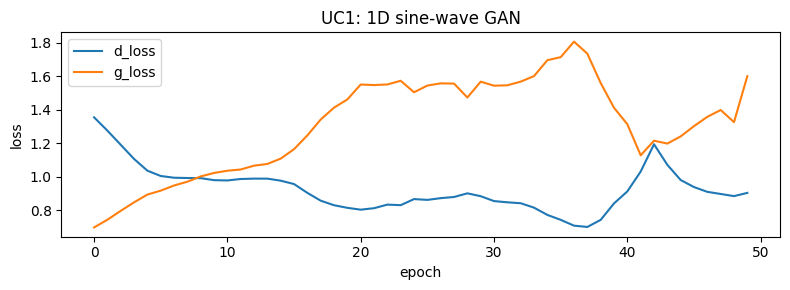

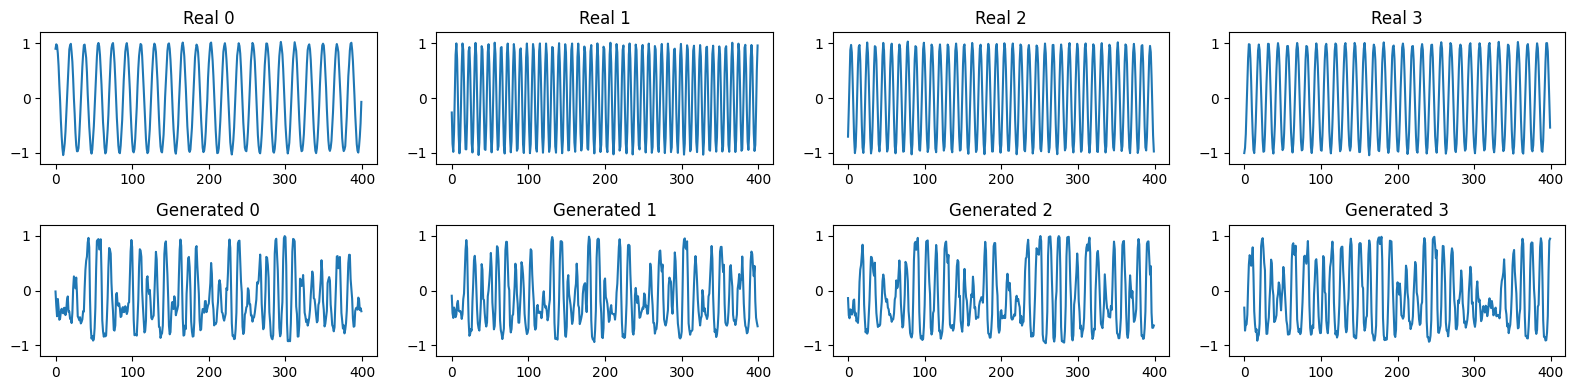

Saved 4 1D samples to output/


In [8]:
def plot_gan_losses(history: dict, title: str = "GAN losses"):
    fig, ax = plt.subplots(figsize=(8, 3))
    ax.plot(history["d_loss"], label="d_loss")
    ax.plot(history["g_loss"], label="g_loss")
    ax.set_xlabel("epoch")
    ax.set_ylabel("loss")
    ax.set_title(title)
    ax.legend()
    plt.tight_layout()
    plt.show()


plot_gan_losses(history_1d, title="UC1: 1D sine-wave GAN")

z = torch.randn(4, LATENT_DIM_1D)
fake_1d = generator_1d(z, training=False).detach().cpu().numpy()

fig, axes = plt.subplots(2, 4, figsize=(16, 4))
for i in range(4):
    axes[0, i].plot(x_real_1d[i, :PLOT_WINDOW, 0])
    axes[0, i].set_title(f"Real {i}")
    axes[0, i].set_ylim(-1.2, 1.2)
    axes[1, i].plot(fake_1d[i, :PLOT_WINDOW, 0])
    axes[1, i].set_title(f"Generated {i}")
    axes[1, i].set_ylim(-1.2, 1.2)
plt.tight_layout()
plt.show()

for i, wav in enumerate(fake_1d):
    waveform = torch.tensor(wav.squeeze(), dtype=torch.float32).unsqueeze(0)
    torchaudio.save(str(OUTPUT_DIR / f"uc1_generated_{i}.wav"), waveform, SAMPLE_RATE_1D)
print(f"Saved {len(fake_1d)} 1D samples to {OUTPUT_DIR}/")

if torch.cuda.is_available():
    torch.cuda.empty_cache()

## Use Case 2: Spectrogram Audio Generation (Spoken Digits)

Generating raw 1D audio coherently is hard because the network has to model long sequences point-by-point. The standard trick is to convert audio into a 2D **mel-spectrogram** (time × frequency), train an image-style DCGAN on those, then invert the spectrogram back to a waveform.

We use the **Free Spoken Digit Dataset (FSDD)** — ~3000 short `.wav` files of digits 0–9 spoken by 6 speakers at 8 kHz. We load it via [Activeloop Hub](https://activeloop.ai/), which streams the data without a git clone.

### Download dataset

In [11]:
path = kagglehub.dataset_download("joserzapata/free-spoken-digit-dataset-fsdd")
print("Path to dataset files:", path)

class FSDDDDataset(Dataset):
    def __init__(self, data_path, sample_rate, duration):
        self.file_list = glob(os.path.join(data_path, "**/*.wav"), recursive=True)
        self.sr = sample_rate
        self.length = int(sample_rate * duration)

    def __len__(self):
        return len(self.file_list)

    def __getitem__(self, idx):
        path = self.file_list[idx]
        audio, _ = librosa.load(path, sr=self.sr)
        if len(audio) < self.length:
            audio = librosa.util.pad_center(audio, size=self.length)
        else:
            audio = audio[:self.length]
        label = int(os.path.basename(path).split('_')[0])
        return torch.tensor(audio, dtype=torch.float32), torch.tensor(label, dtype=torch.long)

ds_raw = FSDDDDataset(path, SAMPLE_RATE_1D, DURATION_1D)

n_train = int(0.8 * len(ds_raw))
n_test  = len(ds_raw) - n_train
train_ds, test_ds = random_split(
    ds_raw, [n_train, n_test],
    generator=torch.Generator().manual_seed(42),
)

train_loader = DataLoader(train_ds, batch_size=256, shuffle=True)
test_loader  = DataLoader(test_ds,  batch_size=256, shuffle=False)

print(f"Train: {n_train} samples | Test: {n_test} samples")

Path to dataset files: /home/rojikaru/.cache/kagglehub/datasets/joserzapata/free-spoken-digit-dataset-fsdd/versions/1
Train: 2400 samples | Test: 600 samples


### Mel-spectrogram preprocessing

Each clip is resampled to 8 kHz, converted to a mel-spectrogram, log-scaled to dB, normalized to `[-1, 1]`, and padded/cropped to a fixed `64 × 64` grid so we can treat them as single-channel images.

Spectrogram dataset shape: (2400, 64, 64, 1), range: [-1.00, 1.00]


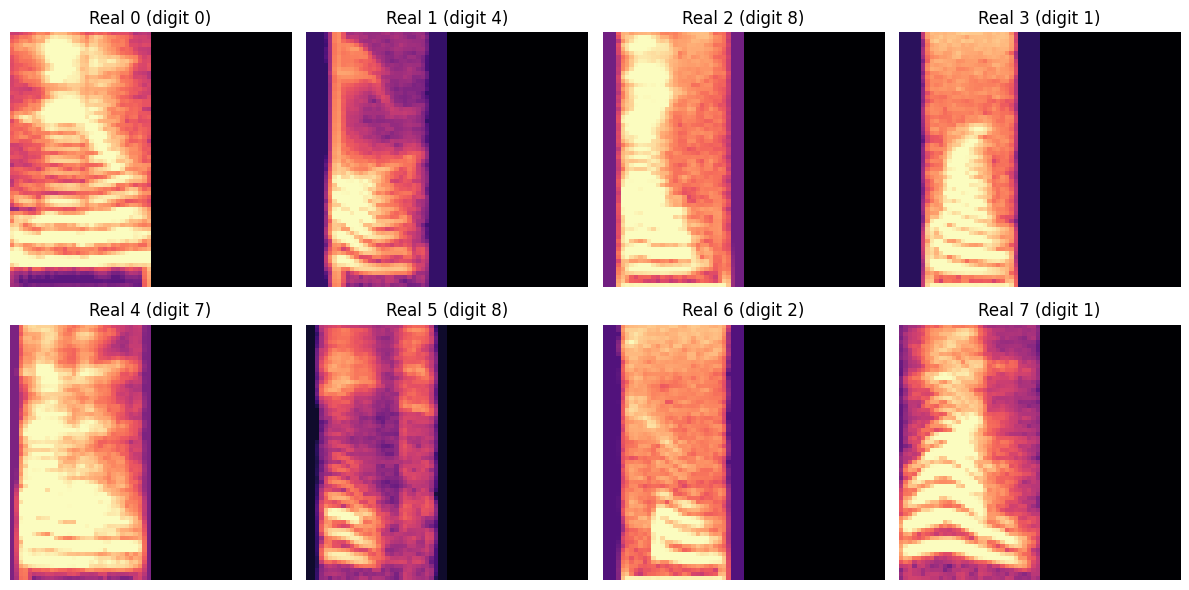

In [12]:
SAMPLE_RATE_2D = 8000
N_FFT = 512
HOP_LENGTH = 128
N_MELS = 64
TARGET_LEN = 64
DB_FLOOR = -80.0

mel_transform = T.MelSpectrogram(
    sample_rate=SAMPLE_RATE_2D,
    n_fft=N_FFT,
    hop_length=HOP_LENGTH,
    n_mels=N_MELS,
    power=2.0,
)
amp_to_db = T.AmplitudeToDB(stype="power", top_db=80)


def waveform_to_melspec(waveform: torch.Tensor) -> np.ndarray:
    if waveform.dim() == 1:
        waveform = waveform.unsqueeze(0)
    if waveform.shape[0] > 1:
        waveform = waveform.mean(dim=0, keepdim=True)
    mel = mel_transform(waveform.float())
    mel_db = amp_to_db(mel).squeeze(0).numpy()
    if mel_db.shape[1] < TARGET_LEN:
        pad = TARGET_LEN - mel_db.shape[1]
        mel_db = np.pad(mel_db, ((0, 0), (0, pad)), constant_values=DB_FLOOR)
    else:
        mel_db = mel_db[:, :TARGET_LEN]
    return mel_db


def normalize_db(spec: np.ndarray) -> np.ndarray:
    """Map dB range [-80, 0] to [-1, 1]."""
    return np.clip((spec - DB_FLOOR / 2) / (-DB_FLOOR / 2), -1.0, 1.0)


def denormalize_db(spec: np.ndarray) -> np.ndarray:
    """Inverse of normalize_db: [-1, 1] back to dB range."""
    return spec * (-DB_FLOOR / 2) + DB_FLOOR / 2


specs = []
labels_list = []
for audio_batch, label_batch in train_loader:
    for waveform, label in zip(audio_batch, label_batch):
        if waveform.abs().max() > 1.5:
            waveform = waveform / 32768.0
        specs.append(normalize_db(waveform_to_melspec(waveform)))
        labels_list.append(label.item())
specs = np.stack(specs).astype(np.float32)[..., np.newaxis]
print(f"Spectrogram dataset shape: {specs.shape}, range: [{specs.min():.2f}, {specs.max():.2f}]")

fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for i, ax in enumerate(axes.flat):
    ax.imshow(specs[i, ..., 0], origin="lower", aspect="auto", cmap="magma")
    ax.set_title(f"Real {i} (digit {labels_list[i]})")
    ax.axis("off")
plt.tight_layout()
plt.show()

### DCGAN architecture

In [16]:
LATENT_DIM_2D = 100


def build_generator_2d() -> Sequential:
    model = Sequential(name="generator_2d")
    model.add(Input(shape=(LATENT_DIM_2D,)))
    model.add(Dense(4 * 4 * 256))
    model.add(LeakyReLU(0.2))
    model.add(Reshape((4, 4, 256)))
    model.add(Conv2DTranspose(128, 4, strides=2, padding="same"))   # 8x8
    model.add(BatchNormalization())
    model.add(LeakyReLU(0.2))
    model.add(Conv2DTranspose(64, 4, strides=2, padding="same"))    # 16x16
    model.add(BatchNormalization())
    model.add(LeakyReLU(0.2))
    model.add(Conv2DTranspose(32, 4, strides=2, padding="same"))    # 32x32
    model.add(BatchNormalization())
    model.add(LeakyReLU(0.2))
    model.add(Conv2DTranspose(1, 4, strides=2, padding="same", activation="tanh"))  # 64x64
    return model


def build_discriminator_2d(use_sigmoid: bool = True) -> Sequential:
    model = Sequential(name="discriminator_2d")
    model.add(Input(shape=(N_MELS, TARGET_LEN, 1)))
    model.add(Conv2D(32, 4, strides=2, padding="same"))
    model.add(LeakyReLU(0.2))
    model.add(Dropout(0.3))
    model.add(Conv2D(64, 4, strides=2, padding="same"))
    model.add(LeakyReLU(0.2))
    model.add(Dropout(0.3))
    model.add(Conv2D(128, 4, strides=2, padding="same"))
    model.add(LeakyReLU(0.2))
    model.add(Dropout(0.3))
    model.add(Flatten())
    model.add(Dense(1, activation="sigmoid" if use_sigmoid else None))
    return model


generator_2d = build_generator_2d()
discriminator_2d = build_discriminator_2d()
generator_2d.summary()
discriminator_2d.summary()

Model: "generator_2d"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_6 (Dense)                 │ (None, 4096)           │       413,696 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_20 (LeakyReLU)      │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape_4 (Reshape)             │ (None, 4, 4, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_8              │ (None, 8, 8, 128)      │       524,416 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_10          │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_21 (LeakyReLU)      │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_9              │ (None, 16, 16, 64)     │       131,136 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_11          │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_22 (LeakyReLU)      │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_10             │ (None, 32, 32, 32)     │        32,800 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_12          │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_23 (LeakyReLU)      │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_11             │ (None, 64, 64, 1)      │           513 │
│ (Conv2DTranspose)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,103,457 (4.21 MB)

 Trainable params: 1,103,009 (4.21 MB)

 Non-trainable params: 448 (1.75 KB)

Model: "discriminator_2d"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)               │ (None, 32, 32, 32)     │           544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_24 (LeakyReLU)      │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 16, 16, 64)     │        32,832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_25 (LeakyReLU)      │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 8, 8, 128)      │       131,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_26 (LeakyReLU)      │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 8192)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 1)              │         8,193 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 172,769 (674.88 KB)

 Trainable params: 172,769 (674.88 KB)

 Non-trainable params: 0 (0.00 B)

### Train the DCGAN

In [19]:
history_dcgan = train_gan(
    generator_2d,
    discriminator_2d,
    specs,
    LATENT_DIM_2D,
    epochs=80,
)
plot_gan_losses(history_dcgan, title="UC2: DCGAN on FSDD mel-spectrograms")

Epoch   1/80  d_loss=1.3206  g_loss=0.6288
Epoch   5/80  d_loss=1.3598  g_loss=0.7583
Epoch  10/80  d_loss=1.3796  g_loss=0.7881
Epoch  15/80  d_loss=1.3806  g_loss=0.7778
Epoch  20/80  d_loss=1.3806  g_loss=0.7895
Epoch  25/80  d_loss=1.3927  g_loss=0.7890
Epoch  30/80  d_loss=1.3833  g_loss=0.7982


OutOfMemoryError: Exception encountered when calling Dropout.call().

[1mCUDA out of memory. Tried to allocate 32.00 MiB. GPU 0 has a total capacity of 3.68 GiB of which 7.44 MiB is free. Process 1460 has 46.04 MiB memory in use. Including non-PyTorch memory, this process has 3.58 GiB memory in use. Of the allocated memory 3.33 GiB is allocated by PyTorch, and 154.92 MiB is reserved by PyTorch but unallocated. If reserved but unallocated memory is large try setting PYTORCH_CUDA_ALLOC_CONF=expandable_segments:True to avoid fragmentation.  See documentation for Memory Management  (https://docs.pytorch.org/docs/stable/notes/cuda.html#optimizing-memory-usage-with-pytorch-cuda-alloc-conf)[0m

Arguments received by Dropout.call():
  • inputs=torch.Tensor(shape=torch.Size([256, 32, 32, 32]), dtype=float32)
  • training=True

### Generated spectrograms vs real

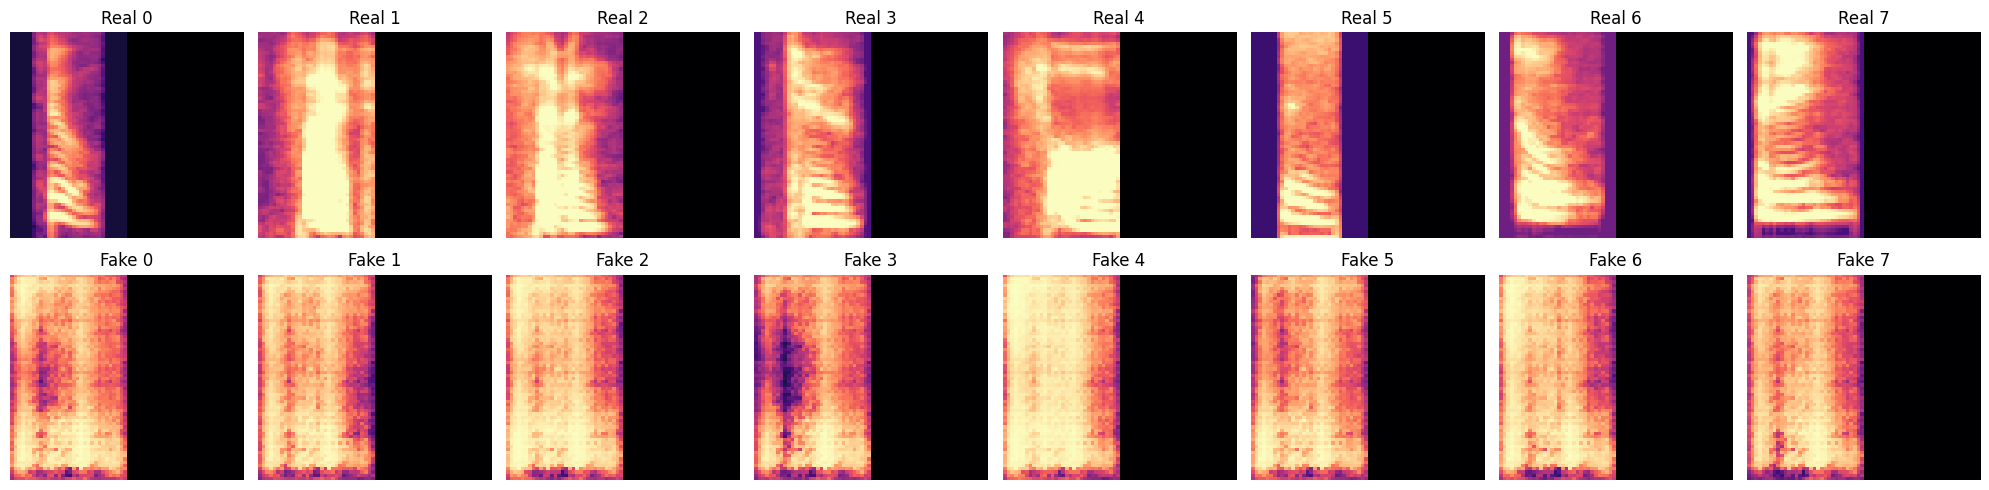

In [ ]:
def sample_specs(generator, latent_dim: int, n: int = 8) -> np.ndarray:
    z = torch.randn(n, latent_dim)
    return generator(z, training=False).detach().cpu().numpy()


fake_specs = sample_specs(generator_2d, LATENT_DIM_2D, n=8)

fig, axes = plt.subplots(2, 8, figsize=(20, 5))
for i in range(8):
    axes[0, i].imshow(specs[i, ..., 0], origin="lower", aspect="auto", cmap="magma")
    axes[0, i].set_title(f"Real {i}")
    axes[0, i].axis("off")
    axes[1, i].imshow(fake_specs[i, ..., 0], origin="lower", aspect="auto", cmap="magma")
    axes[1, i].set_title(f"Fake {i}")
    axes[1, i].axis("off")
plt.tight_layout()
plt.show()

### Reconstruct audio from generated spectrograms

A mel-spectrogram drops phase information, so we cannot invert it perfectly. The pipeline:

1. Un-normalize from `[-1, 1]` back to dB.
2. Convert dB to power amplitude.
3. `InverseMelScale` to estimate the linear (STFT-magnitude) spectrogram.
4. `GriffinLim` to estimate phase and reconstruct a 1D waveform.

The result will sound robotic — that is expected from phase reconstruction.

In [14]:
inverse_mel = T.InverseMelScale(
    n_stft=N_FFT // 2 + 1,
    n_mels=N_MELS,
    sample_rate=SAMPLE_RATE_2D,
)
griffin_lim = T.GriffinLim(
    n_fft=N_FFT,
    hop_length=HOP_LENGTH,
    n_iter=32,
    power=1.0,
)


def spec_to_audio(spec_norm: np.ndarray) -> torch.Tensor:
    """Inverse of normalize_db -> dB -> power -> linear-mag -> waveform."""
    db = denormalize_db(spec_norm.squeeze(-1))
    power = 10.0 ** (db / 10.0)               # dB -> power
    mel_power = torch.tensor(power, dtype=torch.float32).unsqueeze(0)  # (1, n_mels, T)
    linear_power = inverse_mel(mel_power)
    linear_mag = torch.sqrt(linear_power.clamp(min=0))
    waveform = griffin_lim(linear_mag)        # (1, samples)
    return waveform


for i, fake in enumerate(fake_specs[:4]):
    wav = spec_to_audio(fake)
    torchaudio.save(str(OUTPUT_DIR / f"uc2_dcgan_{i}.wav"), wav, SAMPLE_RATE_2D)
print(f"Saved 4 DCGAN-reconstructed audio clips to {OUTPUT_DIR}/")

Saved 4 DCGAN-reconstructed audio clips to output/


## Architectural Improvement: Wasserstein GAN (mitigating mode collapse)

DCGANs commonly suffer from **mode collapse**: the generator finds a single output (or a small set) that fools the discriminator and repeats it forever. With FSDD this often shows up as the model only learning one or two digits.

The **Wasserstein GAN** (Arjovsky et al., 2017) replaces the binary cross-entropy game with the Earth Mover's distance. The "discriminator" becomes a **critic** that outputs a real-valued score:

$$
L_D = \mathbb{E}_{x \sim p_{\text{data}}}[D(x)] - \mathbb{E}_{z}[D(G(z))], \qquad L_G = -\mathbb{E}_{z}[D(G(z))]
$$

To enforce the Lipschitz constraint required by the W-distance, we **clip the critic's weights** to `[-0.01, 0.01]` after each update. The original paper also recommends `RMSprop(lr=5e-5)` over Adam.

In [13]:
def train_wgan(
    generator,
    critic,
    real_data: np.ndarray,
    latent_dim: int,
    epochs: int = 80,
    batch_size: int = 128,
    n_critic: int = 5,
    clip_value: float = 0.01,
    lr: float = 5e-5,
):
    """WGAN with weight clipping (Arjovsky et al., 2017). Tuned for ~4 GB VRAM."""
    g_opt = RMSprop(learning_rate=lr)
    c_opt = RMSprop(learning_rate=lr)

    real_t = torch.tensor(real_data)
    n = real_t.shape[0]
    history = {"c_loss": [], "g_loss": [], "w_dist": []}

    for epoch in range(epochs):
        idx = torch.randperm(n)
        c_losses, g_losses, w_dists = [], [], []
        step = 0

        for start in range(0, n - batch_size + 1, batch_size):
            real_batch = real_t[idx[start : start + batch_size]]
            bs = real_batch.shape[0]

            # ---- Critic step ----
            z = torch.randn(bs, latent_dim)
            fake_batch = generator(z, training=True).detach()
            c_real = critic(real_batch, training=True)
            c_fake = critic(fake_batch, training=True)
            c_real_mean = ops.mean(c_real)
            c_fake_mean = ops.mean(c_fake)
            c_loss = -(c_real_mean - c_fake_mean)

            critic.zero_grad()
            c_loss.backward()
            c_grads = [v.value.grad for v in critic.trainable_weights]
            with torch.no_grad():
                c_opt.apply(c_grads, critic.trainable_weights)
                for w in critic.trainable_weights:
                    w.assign(ops.clip(w, -clip_value, clip_value))

            c_losses.append(c_loss.detach().item())
            w_dists.append((c_real_mean - c_fake_mean).detach().item())
            del c_loss, c_real, c_fake, fake_batch
            step += 1

            # ---- Generator step every n_critic critic steps ----
            if step % n_critic == 0:
                z = torch.randn(bs, latent_dim)
                fake_batch = generator(z, training=True)
                c_fake = critic(fake_batch, training=True)
                g_loss = -ops.mean(c_fake)

                generator.zero_grad()
                g_loss.backward()
                g_grads = [v.value.grad for v in generator.trainable_weights]
                with torch.no_grad():
                    g_opt.apply(g_grads, generator.trainable_weights)
                g_losses.append(g_loss.detach().item())
                del g_loss, c_fake, fake_batch

        if torch.cuda.is_available():
            torch.cuda.empty_cache()

        history["c_loss"].append(float(np.mean(c_losses)))
        history["g_loss"].append(float(np.mean(g_losses)) if g_losses else float("nan"))
        history["w_dist"].append(float(np.mean(w_dists)))
        if (epoch + 1) % 5 == 0 or epoch == 0:
            print(f"Epoch {epoch + 1:3d}/{epochs}  c_loss={history['c_loss'][-1]:.4f}  g_loss={history['g_loss'][-1]:.4f}  w_dist={history['w_dist'][-1]:.4f}")

    return history


generator_wgan = build_generator_2d()
critic_wgan = build_discriminator_2d(use_sigmoid=False)
critic_wgan._name = "critic_wgan"

history_wgan = train_wgan(
    generator_wgan,
    critic_wgan,
    specs,
    LATENT_DIM_2D,
)

Epoch   1/80  c_loss=0.0030  g_loss=0.0007  w_dist=-0.0030
Epoch   5/80  c_loss=-0.2961  g_loss=0.0063  w_dist=0.2961
Epoch  10/80  c_loss=-4.0373  g_loss=-0.9755  w_dist=4.0373
Epoch  15/80  c_loss=-12.4283  g_loss=-8.2809  w_dist=12.4283
Epoch  20/80  c_loss=-23.1786  g_loss=-25.6040  w_dist=23.1786
Epoch  25/80  c_loss=-24.9080  g_loss=-39.7454  w_dist=24.9080
Epoch  30/80  c_loss=-20.3747  g_loss=-39.6446  w_dist=20.3747
Epoch  35/80  c_loss=-18.3239  g_loss=-35.9659  w_dist=18.3239
Epoch  40/80  c_loss=-16.8263  g_loss=-32.2911  w_dist=16.8263
Epoch  45/80  c_loss=-15.1053  g_loss=-30.3308  w_dist=15.1053
Epoch  50/80  c_loss=-12.6356  g_loss=-30.0701  w_dist=12.6356
Epoch  55/80  c_loss=-10.4670  g_loss=-30.9919  w_dist=10.4670
Epoch  60/80  c_loss=-8.8105  g_loss=-30.2150  w_dist=8.8105
Epoch  65/80  c_loss=-7.7911  g_loss=-30.0449  w_dist=7.7911
Epoch  70/80  c_loss=-6.0666  g_loss=-30.4345  w_dist=6.0666
Epoch  75/80  c_loss=-5.3808  g_loss=-28.5805  w_dist=5.3808
Epoch  80/80

### Comparison: DCGAN vs WGAN

Two views of the comparison:

1. **Loss curves**: WGAN's Wasserstein-distance estimate should decline more smoothly than DCGAN's BCE losses, which oscillate.
2. **Sample diversity**: project the mean of each generated spectrogram into 2D via PCA. A wider spread = more diversity, a tight cluster = mode collapse.

NameError: name 'history_dcgan' is not defined

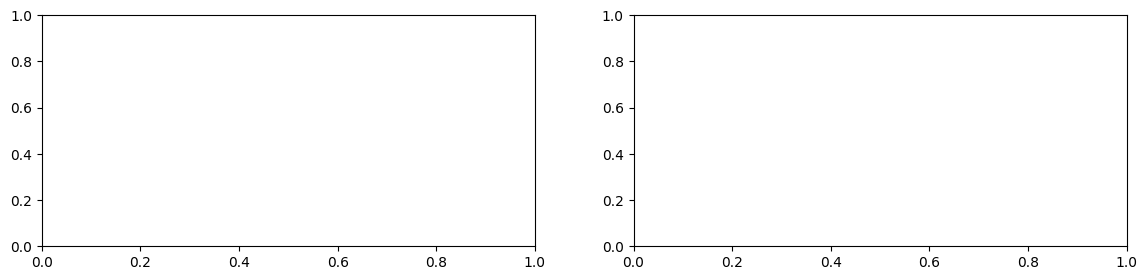

In [ ]:
from sklearn.decomposition import PCA

# Loss / Wasserstein-distance curves
fig, axes = plt.subplots(1, 2, figsize=(14, 3))
axes[0].plot(history_dcgan["d_loss"], label="d_loss")
axes[0].plot(history_dcgan["g_loss"], label="g_loss")
axes[0].set_title("DCGAN BCE losses")
axes[0].set_xlabel("epoch")
axes[0].legend()
axes[1].plot(history_wgan["w_dist"], label="W-distance estimate", color="C2")
axes[1].plot(history_wgan["g_loss"], label="g_loss", color="C3")
axes[1].set_title("WGAN training signal")
axes[1].set_xlabel("epoch")
axes[1].legend()
plt.tight_layout()
plt.show()

# Side-by-side spectrogram grids
dcgan_samples = sample_specs(generator_2d, LATENT_DIM_2D, n=8)
wgan_samples = sample_specs(generator_wgan, LATENT_DIM_2D, n=8)

fig, axes = plt.subplots(2, 8, figsize=(20, 5))
for i in range(8):
    axes[0, i].imshow(dcgan_samples[i, ..., 0], origin="lower", aspect="auto", cmap="magma")
    axes[0, i].set_title(f"DCGAN {i}")
    axes[0, i].axis("off")
    axes[1, i].imshow(wgan_samples[i, ..., 0], origin="lower", aspect="auto", cmap="magma")
    axes[1, i].set_title(f"WGAN {i}")
    axes[1, i].axis("off")
plt.tight_layout()
plt.show()

# Diversity via PCA over 100 generated samples
def project_samples(generator, latent_dim: int, n: int = 100) -> np.ndarray:
    z = torch.randn(n, latent_dim)
    out = generator(z, training=False).detach().cpu().numpy()
    return out.reshape(n, -1)


pca = PCA(n_components=2)
all_samples = np.vstack([
    project_samples(generator_2d, LATENT_DIM_2D, n=100),
    project_samples(generator_wgan, LATENT_DIM_2D, n=100),
])
proj = pca.fit_transform(all_samples)

plt.figure(figsize=(8, 6))
plt.scatter(proj[:100, 0], proj[:100, 1], label="DCGAN", alpha=0.6)
plt.scatter(proj[100:, 0], proj[100:, 1], label="WGAN", alpha=0.6)
plt.title("PCA projection of 100 generated samples per model")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.legend()
plt.tight_layout()
plt.show()

# Save 4 WGAN audio samples for listening
for i, fake in enumerate(wgan_samples[:4]):
    wav = spec_to_audio(fake)
    torchaudio.save(str(OUTPUT_DIR / f"uc3_wgan_{i}.wav"), wav, SAMPLE_RATE_2D)
print(f"Saved 4 WGAN-reconstructed audio clips to {OUTPUT_DIR}/")

## Conclusions

- **Use Case 1** showed that even a small Conv1D-based GAN can recover the structure of a simple periodic signal directly in the time domain.
- **Use Case 2** moved to the more practical 2D mel-spectrogram representation: the DCGAN learns digit-shaped energy distributions, but BCE loss curves are noisy and mode collapse is easy to trigger.
- **Use Case 3** showed that switching to Wasserstein loss with weight clipping produces a smoother, more interpretable training signal (the W-distance estimate correlates with sample quality) and visibly broader sample diversity in the PCA scatter.
- **Audio reconstruction** via `InverseMelScale` + `GriffinLim` always sounds robotic — the next step would be a learned vocoder (HiFi-GAN, MelGAN) instead of phase-estimation Griffin-Lim. A second improvement would be conditioning the generator on the digit label (cGAN), which directly addresses mode collapse by anchoring each mode to a specific class.